
# Model 12: Hebbian Learning in a Neural Network

## Objective

Extend the interconnected neural network developed in Model 11 by introducing activity-dependent synaptic plasticity.

Unlike Model 11, where synaptic weights remained fixed, this model allows connections between neurons to strengthen through repeated coactivation.

Our goal is to investigate how neural networks can learn associations through experience and how these learned connections influence future neural activity.

## Research Questions

1. Can repeated activation of a group of neurons strengthen the connections between them?
2. How does repeated exposure affect the strength and structure of a neural network?
3. Can learned connections allow the network to activate associated neurons when given only partial stimulation?

## Hypothesis

Repeated coactivation of neurons will strengthen their mutual synaptic connections through Hebbian learning.

As training progresses, the network will develop stronger connections between frequently coactivated neurons, potentially allowing partial stimulation to reactivate previously learned activity patterns.

## Model Assumptions

- The network consists of six interconnected neurons.
- Neurons have binary activity states: 0 (inactive) or 1 (active).
- Synaptic weights are initially zero and constrained between 0 and 1.
- Connections strengthen according to bounded Hebbian learning.
- Self-connections are not permitted.
- Synaptic decay and inhibitory learning are excluded from this initial model.
- During training, neural activity patterns are externally imposed to isolate the learning mechanism.



## Mathematical Foundation

### Hebbian Learning

Hebbian learning is based on the principle that neurons that activate together strengthen their synaptic connections.

We use the bounded Hebbian learning rule introduced in Model 8:

$$
\Delta w_{ij} = \eta x_i x_j(1-w_{ij})
$$

where:

- $w_{ij}$ represents the connection strength from neuron $j$ to neuron $i$.
- $\eta$ represents the learning rate.
- $x_i$ represents the activity of the receiving neuron.
- $x_j$ represents the activity of the sending neuron.

The resulting update equation is:

$$
w_{ij}(t+1) = w_{ij}(t) + \eta x_i(t)x_j(t)(1-w_{ij}(t))
$$

The term $(1-w_{ij})$ prevents connection strengths from growing indefinitely.

### Matrix Representation

For a network of $n$ neurons, we represent neural activities using a vector:

$$
\mathbf{x} =
\begin{bmatrix}
x_1\\
x_2\\
\vdots\\
x_n
\end{bmatrix}
$$

Synaptic connections are represented by the weight matrix:

$$
W \in \mathbb{R}^{n \times n}
$$

We can calculate pairwise neural coactivation using the outer product:

$$
C = \mathbf{x}\mathbf{x}^T
$$

This produces a matrix where:

$$
C_{ij} = x_i x_j
$$

Using elementwise multiplication, the Hebbian learning rule becomes:

$$
\boxed{
W_{t+1} = W_t + \eta(\mathbf{x}\mathbf{x}^T)\odot(1-W_t)
}
$$

where $\odot$ represents elementwise multiplication.

We additionally set all diagonal entries to zero to prevent self-connections.



## Experiment 1: Learning a Neural Activity Pattern

### Objective

Investigate whether repeatedly presenting the same neural activity pattern strengthens connections between coactivated neurons.

### Experimental Setup

We initialize a network of six neurons with all synaptic weights equal to zero.

We repeatedly present the activity pattern:

$$
\mathbf{x} =
\begin{bmatrix}
1 & 1 & 0 & 1 & 0 & 0
\end{bmatrix}^T
$$

Neurons 1, 2, and 4 are active, while the remaining neurons are inactive.

The network undergoes 40 training epochs using a learning rate of 0.1.

### Prediction

Connections between neurons 1, 2, and 4 will strengthen with repeated training, approaching a maximum weight of 1.

Connections involving inactive neurons will remain at zero.


In [4]:

import numpy as np
import matplotlib.pyplot as plt

# Model parameters
num_neurons = 6
learning_rate = 0.1
epochs = 40

# Neural activity pattern
pattern = np.array([1, 1, 0, 1, 0, 0])

# Initialize synaptic weights
W = np.zeros((num_neurons, num_neurons))

# Record the initial weights
weight_history = [W.copy()]

# Training
for epoch in range(epochs):
    coactivation = np.outer(pattern, pattern)

    # Bounded Hebbian learning
    W += learning_rate * coactivation * (1 - W)

    # Prevent self-connections
    np.fill_diagonal(W, 0)

    weight_history.append(W.copy())

weight_history = np.array(weight_history)

print("Final weight matrix:")
print(np.round(W, 3))


Final weight matrix:
[[0.    0.985 0.    0.985 0.    0.   ]
 [0.985 0.    0.    0.985 0.    0.   ]
 [0.    0.    0.    0.    0.    0.   ]
 [0.985 0.985 0.    0.    0.    0.   ]
 [0.    0.    0.    0.    0.    0.   ]
 [0.    0.    0.    0.    0.    0.   ]]


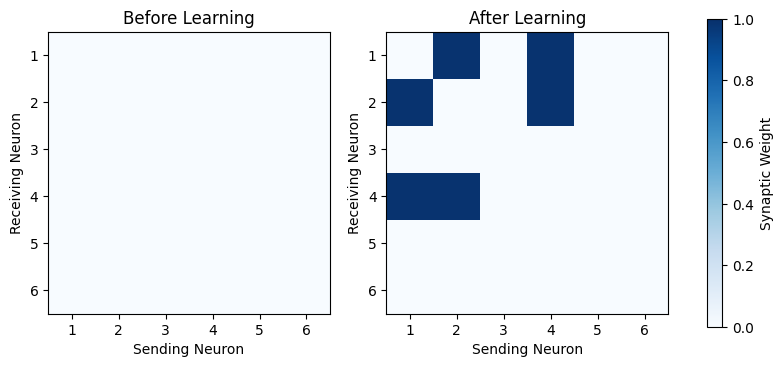

In [5]:

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

titles = ["Before Learning", "After Learning"]
matrices = [weight_history[0], weight_history[-1]]

for ax, matrix, title in zip(axes, matrices, titles):
    im = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)

    ax.set_title(title)
    ax.set_xlabel("Sending Neuron")
    ax.set_ylabel("Receiving Neuron")

    ax.set_xticks(range(num_neurons))
    ax.set_yticks(range(num_neurons))

    ax.set_xticklabels(range(1, num_neurons + 1))
    ax.set_yticklabels(range(1, num_neurons + 1))

fig.colorbar(im, ax=axes, label="Synaptic Weight")

plt.show()


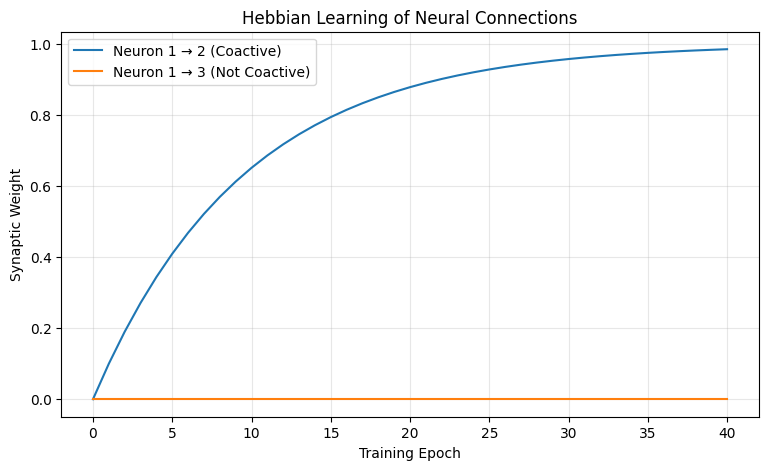

In [6]:

plt.figure(figsize=(9, 5))

# Coactive neurons
plt.plot(
    weight_history[:, 1, 0],
    label="Neuron 1 → 2 (Coactive)"
)

# Neurons that are not coactive
plt.plot(
    weight_history[:, 2, 0],
    label="Neuron 1 → 3 (Not Coactive)"
)

plt.xlabel("Training Epoch")
plt.ylabel("Synaptic Weight")
plt.title("Hebbian Learning of Neural Connections")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



## Experiment 1: Results and Discussion

### Observations

The network successfully strengthened synaptic connections between neurons that were repeatedly active together.

The weight matrix initially contained only zeros. After 40 training epochs, strong connections emerged between neurons 1, 2, and 4, while connections involving inactive neurons remained unchanged.

The learning curve also demonstrates that synaptic strengthening slows as weights approach their maximum value of 1.

For connections that are consistently coactive, the theoretical weight after $t$ epochs is:

$$
w_t = 1-(1-\eta)^t
$$

With a learning rate of 0.1 and 40 epochs:

$$
w_{40} = 1-0.9^{40} \approx 0.9852
$$

This agrees with the simulated connection strengths.

### Interpretation

These results demonstrate that repeated neural coactivation can produce structured synaptic connections through bounded Hebbian learning.

The network selectively strengthens connections between coactive neurons without strengthening unrelated connections.

However, this experiment only demonstrates synaptic learning. We have not yet established whether the resulting network can use its learned connections to retrieve an activity pattern from incomplete input.

### Next Experiment

We will investigate whether stimulating only part of a previously learned neural activity pattern allows the network to reconstruct the full pattern through its learned synaptic connections.
